<a href="https://colab.research.google.com/github/jufribeiro17-wq/FIAP-DA/blob/main/Desafio_Analytics_e_Storytelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Análise dos casos de dengue no Estado de São Paulo entre 2013 e 2023

In [ ]:
#1. Importação das bibliotecas para análise de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12,6)

print ("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [7]:
#2. Upload do arquivo de dados
nome_do_arquivo = 'Base de Dados Dengue.xlsx'

df = pd.read_excel(nome_do_arquivo)

In [9]:
#3. Conhecendo a base
display(df.head())

df.info()



,municipio,uf,data_infeccoes,qtd_infeccoes
0,ALTA FLORESTA D'OESTE,RO,2013-01-01,34
1,ALTA FLORESTA D'OESTE,RO,2013-02-01,44
2,ALTA FLORESTA D'OESTE,RO,2013-03-01,15
3,ALTA FLORESTA D'OESTE,RO,2013-04-01,4
4,ALTA FLORESTA D'OESTE,RO,2013-05-01,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 728772 entries, 0 to 728771
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   municipio       728772 non-null  object        
 1   uf              728772 non-null  object        
 2   data_infeccoes  728772 non-null  datetime64[ns]
 3   qtd_infeccoes   728772 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 22.2+ MB


In [10]:
# Exibir a lista com os nomes de todas as colunas da base
print(df.columns.tolist())

['municipio', 'uf', 'data_infeccoes', 'qtd_infeccoes']


In [12]:
# 1. Filtrar mantendo apenas as linhas onde a coluna de estado é igual a 'SP'

df_sp = df[df['uf'] == 'SP'].copy()

# 2. Verificar quantas linhas restaram após o filtro
print(f"Total de registros originais no Brasil: {len(df)}")
print(f"Total de registros mantidos em São Paulo: {len(df_sp)}")

# 3. Exibir a distribuição para garantir que só sobrou SP
print("\nVerificação das UFs mantidas na nova base:")
print(df_sp['uf'].value_counts())

Total de registros originais no Brasil: 728772
Total de registros mantidos em São Paulo: 85140

Verificação das UFs mantidas na nova base:
uf
SP    85140
Name: count, dtype: int64


In [13]:
#Salvar a base reduzida

df = df_sp
print("✅ Base de dados configurada com sucesso para os municípios de São Paulo!")
display(df.head())

✅ Base de dados configurada com sucesso para os municípios de São Paulo!


,municipio,uf,data_infeccoes,qtd_infeccoes
430584,ADAMANTINA,SP,2013-01-01,10
430585,ADAMANTINA,SP,2013-02-01,61
430586,ADAMANTINA,SP,2013-03-01,173
430587,ADAMANTINA,SP,2013-04-01,32
430588,ADAMANTINA,SP,2013-05-01,20


--- Contagem de Registros por Região ---
macro_regiao
Interior     81180
Grande SP     2904
Litoral       1056
Name: count, dtype: int64


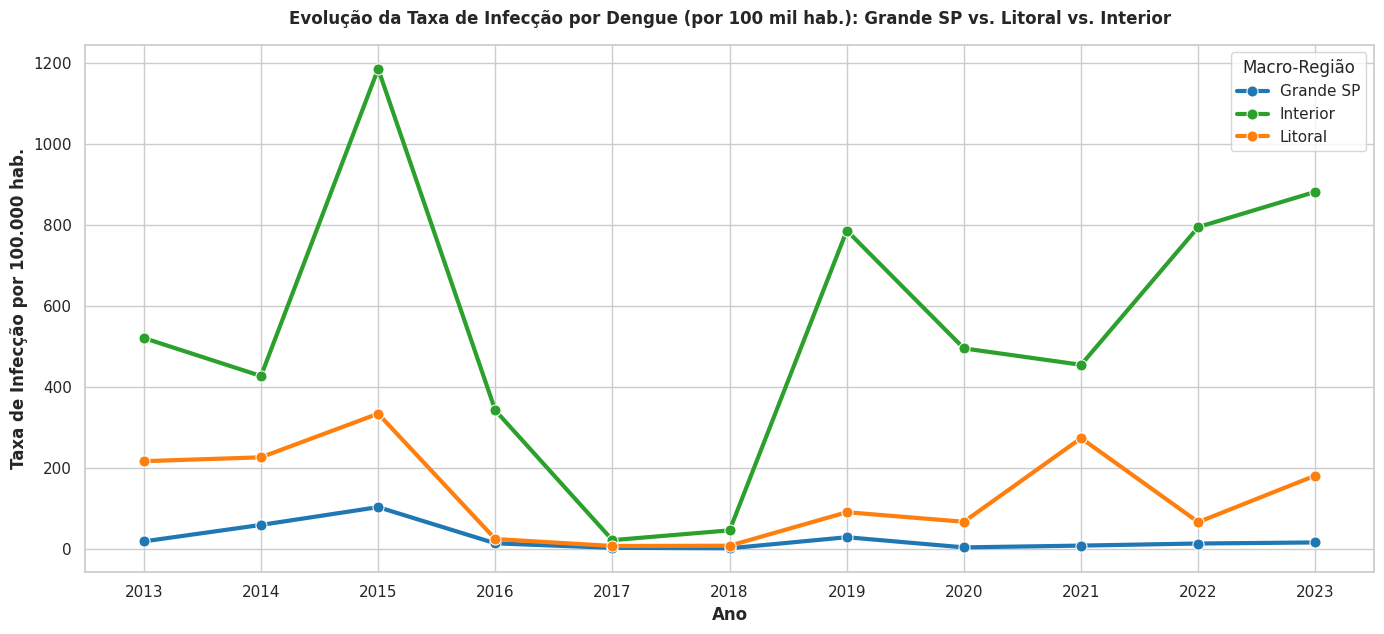

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------------------
# 1. VALIDAÇÃO DOS NOMES DAS COLUNAS
# -------------------------------------------------------------------------
# Ajuste 'municipio' se o nome da coluna no seu DataFrame for diferente
col_mun = 'municipio'
col_uf = 'uf'
col_qtd = 'qtd_infeccoes'
col_data = 'data_infeccoes'

# 2. Filtrar SP
df_sp = df[df[col_uf].astype(str).str.upper().str.strip() == 'SP'].copy()

# Converte data e ajusta ano
df_sp[col_data] = pd.to_datetime(df_sp[col_data])
df_sp['ano'] = df_sp[col_data].dt.year

# -------------------------------------------------------------------------
# 3. LISTAS PADRONIZADAS EM MAIÚSCULAS
# -------------------------------------------------------------------------
rmsp_upper = [m.upper().strip() for m in [
    'São Paulo', 'Guarulhos', 'São Bernardo do Campo', 'Santo André', 'Osasco',
    'São Caetano do Sul', 'Diadema', 'Mauá', 'Barueri', 'Carapicuíba', 'Taboão da Serra',
    'Suzano', 'Mogi das Cruzes', 'Itaquaquecetuba', 'Cotia', 'Embu das Artes',
    'Santana de Parnaíba', 'Jandira', 'Itapevi', 'Ferraz de Vasconcelos', 'Poá',
    'Ribeirão Pires', 'Franco da Rocha', 'Francisco Morato', 'Arujá', 'Caieiras',
    'Mairiporã', 'Cajamar', 'Embu-Guaçu', 'Santa Isabel', 'Vargem Grande Paulista',
    'Itapecerica da Serra', 'Rio Grande da Serra', 'Biritiba Mirim', 'Guareí',
    'Pirapora do Bom Jesus', 'Juquitiba', 'Salesópolis', 'São Lourenço da Serra'
]]

litoral_upper = [m.upper().strip() for m in [
    'Santos', 'São Vicente', 'Guarujá', 'Praia Grande', 'Caraguatatuba', 'Ubatuba',
    'São Sebastião', 'Bertioga', 'Itanhaém', 'Peruíbe', 'Ilhabela', 'Cananéia',
    'Iguape', 'Mongaguá', 'Ilha Comprida'
]]

# Cria coluna auxiliar em maiúsculas no DataFrame para garantir o match exato
mun_formatado = df_sp[col_mun].astype(str).str.upper().str.strip()

condicoes = [
    mun_formatado.isin(rmsp_upper),
    mun_formatado.isin(litoral_upper)
]
escolhas = ['Grande SP', 'Litoral']

df_sp['macro_regiao'] = np.select(condicoes, escolhas, default='Interior')

# -------------------------------------------------------------------------
# 4. CHECAGEM DE SEGURANÇA (Ver se as 3 regiões apareceram)
# -------------------------------------------------------------------------
print("--- Contagem de Registros por Região ---")
print(df_sp['macro_regiao'].value_counts())

# -------------------------------------------------------------------------
# 5. CÁLCULO DAS TAXAS E GRÁFICO
# -------------------------------------------------------------------------
df_regiao_ano = df_sp.groupby(['macro_regiao', 'ano'])[col_qtd].sum().reset_index()

populacao_regiao = {
    'Grande SP': 20700000,
    'Litoral': 1900000,
    'Interior': 21800000
}

df_regiao_ano['populacao_est'] = df_regiao_ano['macro_regiao'].map(populacao_regiao)
df_regiao_ano['taxa_por_100k'] = (df_regiao_ano[col_qtd] / df_regiao_ano['populacao_est']) * 100000

# Plotagem do Gráfico
plt.figure(figsize=(14, 6.5))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=df_regiao_ano,
    x='ano',
    y='taxa_por_100k',
    hue='macro_regiao',
    palette={'Grande SP': '#1f77b4', 'Litoral': '#ff7f0e', 'Interior': '#2ca02c'},
    marker='o',
    linewidth=3,
    markersize=8
)

plt.title('Evolução da Taxa de Infecção por Dengue (por 100 mil hab.): Grande SP vs. Litoral vs. Interior', pad=15, fontweight='bold')
plt.xlabel('Ano', fontweight='bold')
plt.ylabel('Taxa de Infecção por 100.000 hab.', fontweight='bold')
plt.xticks(sorted(df_regiao_ano['ano'].unique()))
plt.legend(title='Macro-Região', frameon=True)
plt.tight_layout()

plt.savefig('evolucao_dengue_3_regioes_corrigido.png', dpi=300)
plt.show()

In [14]:
#Segregar por macro regiões

import numpy as np

# 1. Definir as listas de municípios de cada região
# (Os municípios da Grande SP usam a lista oficial da Região Metropolitana de São Paulo - RMSP)
rmsp = [
    'São Paulo', 'Guarulhos', 'São Bernardo do Campo', 'Santo André', 'Osasco',
    'São Caetano do Sul', 'Diadema', 'Mauá', 'Barueri', 'Carapicuíba', 'Taboão da Serra',
    'Suzano', 'Mogi das Cruzes', 'Itaquaquecetuba', 'Cotia', 'Embu das Artes',
    'Santana de Parnaíba', 'Jandira', 'Itapevi', 'Ferraz de Vasconcelos', 'Poá',
    'Ribeirão Pires', 'Franco da Rocha', 'Francisco Morato', 'Arujá', 'Caieiras',
    'Mairiporã', 'Cajamar', 'Embu-Guaçu', 'Santa Isabel', 'Vargem Grande Paulista',
    'Itapecerica da Serra', 'Rio Grande da Serra', 'Biritiba Mirim', 'Guareí',
    'Pirapora do Bom Jesus', 'Juquitiba', 'Salesópolis', 'São Lourenço da Serra'
]

litoral = [
    'Santos', 'São Vicente', 'Guarujá', 'Praia Grande', 'Caraguatatuba', 'Ubatuba',
    'São Sebastião', 'Bertioga', 'Itanhaém', 'Peruíbe', 'Ilhabela', 'Cananéia',
    'Iguape', 'Mongaguá', 'Ilha Comprida'
]

# 2. Tratar espaços extras e padronizar os nomes da coluna de município

coluna_mun = 'municipio'
df[coluna_mun] = df[coluna_mun].astype(str).str.strip()

# 3. Criar as condições de enquadramento
condicoes = [
    df[coluna_mun].isin(rmsp),
    df[coluna_mun].isin(litoral)
]

escolhas = ['Grande SP', 'Litoral']

# 4. Aplicar o np.select: o que não for Grande SP nem Litoral vira 'Interior'
df['macro_regiao'] = np.select(condicoes, escolhas, default='Interior')

# 5. Validar os resultados
print("--- Contagem de registros por Macro-Região ---")
print(df['macro_regiao'].value_counts())

# Exibe amostra das colunas
display(df[[coluna_mun, 'macro_regiao']].head(10))

--- Contagem de registros por Macro-Região ---
macro_regiao
Interior    85140
Name: count, dtype: int64


,municipio,macro_regiao
430584,ADAMANTINA,Interior
430585,ADAMANTINA,Interior
430586,ADAMANTINA,Interior
430587,ADAMANTINA,Interior
430588,ADAMANTINA,Interior
430589,ADAMANTINA,Interior
430590,ADAMANTINA,Interior
430591,ADAMANTINA,Interior
430592,ADAMANTINA,Interior
430593,ADAMANTINA,Interior


--- Resumo das Infecções e Taxas por Macro-Região e Ano ---


,macro_regiao,ano,qtd_infeccoes,populacao_est,taxa_por_100k
0,Interior,2013,121219,21800000,556.050459
1,Interior,2014,109342,21800000,501.568807
2,Interior,2015,286000,21800000,1311.926606
3,Interior,2016,77559,21800000,355.775229
4,Interior,2017,5038,21800000,23.110092
5,Interior,2018,10098,21800000,46.321101
6,Interior,2019,178852,21800000,820.422018
7,Interior,2020,109705,21800000,503.233945
8,Interior,2021,105707,21800000,484.894495
9,Interior,2022,177043,21800000,812.123853


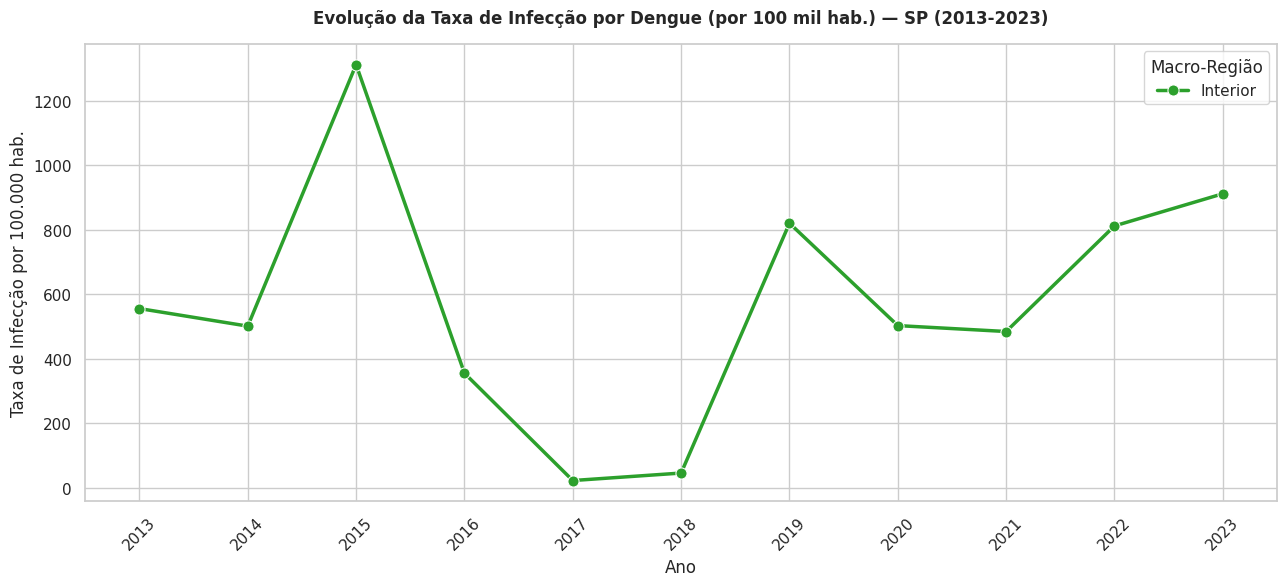

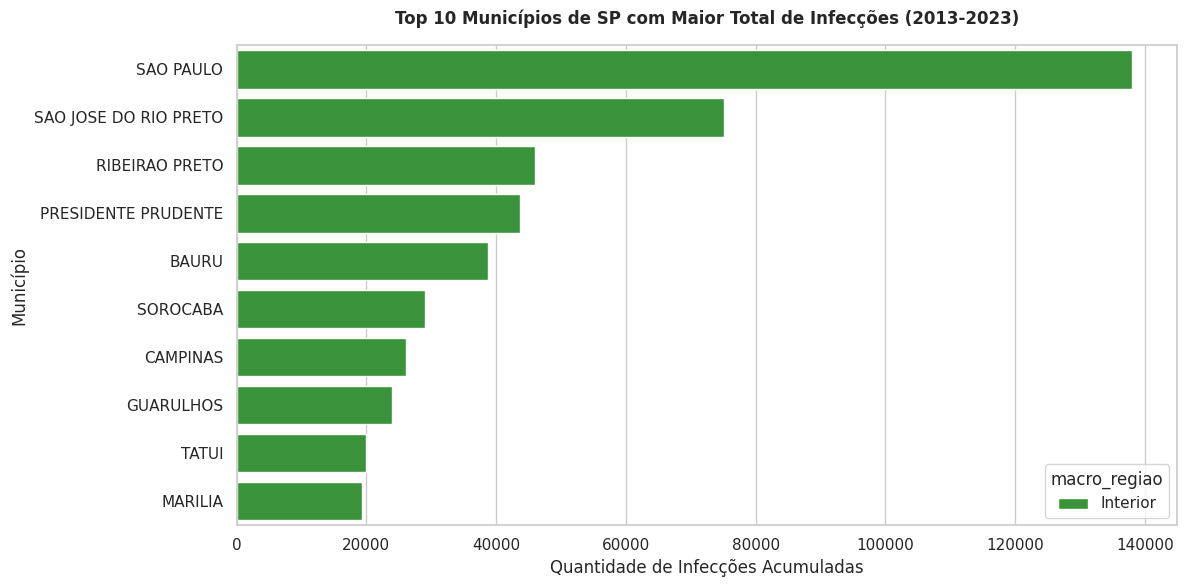

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual profissiona
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 14})

# -------------------------------------------------------------------------
# 1. NOMES DAS COLUNAS
# -------------------------------------------------------------------------
col_uf = 'uf'
col_mun = 'municipio'
col_data = 'data_infeccoes'
col_qtd = 'qtd_infeccoes'

# -------------------------------------------------------------------------
# 2. FILTRAR APENAS SÃO PAULO E AJUSTAR DATAS
# -------------------------------------------------------------------------
# Filtra estado mantendo apenas SP
df_sp = df[df[col_uf].astype(str).str.upper() == 'SP'].copy()

# Converte data e extrai o ano
df_sp[col_data] = pd.to_datetime(df_sp[col_data])
df_sp['ano'] = df_sp[col_data].dt.year
df_sp[col_mun] = df_sp[col_mun].astype(str).str.strip()

# -------------------------------------------------------------------------
# 3. CATEGORIZAÇÃO EM MACRO-REGIÕES
# -------------------------------------------------------------------------
rmsp = [
    'São Paulo', 'Guarulhos', 'São Bernardo do Campo', 'Santo André', 'Osasco',
    'São Caetano do Sul', 'Diadema', 'Mauá', 'Barueri', 'Carapicuíba', 'Taboão da Serra',
    'Suzano', 'Mogi das Cruzes', 'Itaquaquecetuba', 'Cotia', 'Embu das Artes',
    'Santana de Parnaíba', 'Jandira', 'Itapevi', 'Ferraz de Vasconcelos', 'Poá',
    'Ribeirão Pires', 'Franco da Rocha', 'Francisco Morato', 'Arujá', 'Caieiras',
    'Mairiporã', 'Cajamar', 'Embu-Guaçu', 'Santa Isabel', 'Vargem Grande Paulista',
    'Itapecerica da Serra', 'Rio Grande da Serra', 'Biritiba Mirim', 'Guareí',
    'Pirapora do Bom Jesus', 'Juquitiba', 'Salesópolis', 'São Lourenço da Serra'
]

litoral = [
    'Santos', 'São Vicente', 'Guarujá', 'Praia Grande', 'Caraguatatuba', 'Ubatuba',
    'São Sebastião', 'Bertioga', 'Itanhaém', 'Peruíbe', 'Ilhabela', 'Cananéia',
    'Iguape', 'Mongaguá', 'Ilha Comprida'
]

condicoes = [
    df_sp[col_mun].isin(rmsp),
    df_sp[col_mun].isin(litoral)
]
escolhas = ['Grande SP', 'Litoral']

df_sp['macro_regiao'] = np.select(condicoes, escolhas, default='Interior')

# -------------------------------------------------------------------------
# 4. CÁLCULO DA TAXA DE INFECÇÃO POR 100 MIL HABITANTES POR REGIONAL
# -------------------------------------------------------------------------
# Agrupa a quantidade total de infecções por região e por ano
df_regiao_ano = df_sp.groupby(['macro_regiao', 'ano'])[col_qtd].sum().reset_index()

# Dicionário com a população aproximada de referência de cada regional
populacao_regiao = {
    'Grande SP': 20700000,
    'Litoral': 1900000,
    'Interior': 21800000
}

# Mapeia a população correspondente e calcula a taxa por 100k hab.
df_regiao_ano['populacao_est'] = df_regiao_ano['macro_regiao'].map(populacao_regiao)
df_regiao_ano['taxa_por_100k'] = (df_regiao_ano[col_qtd] / df_regiao_ano['populacao_est']) * 100000

print("--- Resumo das Infecções e Taxas por Macro-Região e Ano ---")
display(df_regiao_ano.head(10))

# -------------------------------------------------------------------------
# 5. GRÁFICO 1: EVOLUÇÃO TEMPORAL DA TAXA DE INFECÇÃO (2013-2023)
# -------------------------------------------------------------------------
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=df_regiao_ano,
    x='ano',
    y='taxa_por_100k',
    hue='macro_regiao',
    palette={'Grande SP': '#1f77b4', 'Litoral': '#ff7f0e', 'Interior': '#2ca02c'},
    marker='o',
    linewidth=2.5,
    markersize=8
)

plt.title('Evolução da Taxa de Infecção por Dengue (por 100 mil hab.) — SP (2013-2023)', pad=15, fontweight='bold')
plt.xlabel('Ano')
plt.ylabel('Taxa de Infecção por 100.000 hab.')
plt.xticks(df_regiao_ano['ano'].unique(), rotation=45)
plt.legend(title='Macro-Região', frameon=True)
plt.tight_layout()

# Salva imagem em alta resolução para usar no PDF
plt.savefig('evolucao_taxa_dengue_sp.png', dpi=300)
plt.show()

# -------------------------------------------------------------------------
# 6. GRÁFICO 2: TOP 10 MUNICÍPIOS COM MAIOR VOLUME DE CASOS ACUMULADOS
# -------------------------------------------------------------------------
df_top_mun = df_sp.groupby([col_mun, 'macro_regiao'])[col_qtd].sum().reset_index()
df_top_mun = df_top_mun.sort_values(by=col_qtd, ascending=False).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_top_mun,
    x=col_qtd,
    y=col_mun,
    hue='macro_regiao',
    dodge=False,
    palette={'Grande SP': '#1f77b4', 'Litoral': '#ff7f0e', 'Interior': '#2ca02c'}
)

plt.title('Top 10 Municípios de SP com Maior Total de Infecções (2013-2023)', pad=15, fontweight='bold')
plt.xlabel('Quantidade de Infecções Acumuladas')
plt.ylabel('Município')
plt.tight_layout()

# Salva imagem para o PDF
plt.savefig('top10_municipios_casos.png', dpi=300)
plt.show()

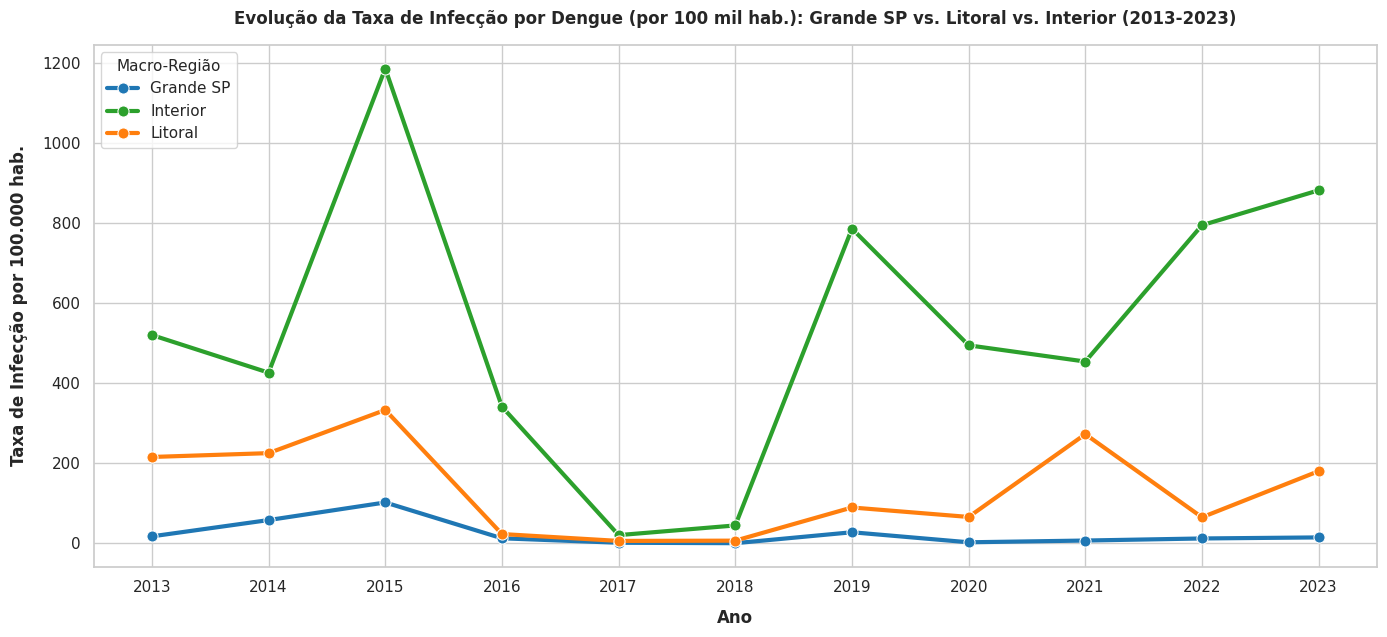

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual profissional para o relatório
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 14})

# -------------------------------------------------------------------------
# GRÁFICO DE EVOLUÇÃO TEMPORAL (LINHAS) — 3 MACRO-REGIÕES DE SP
# -------------------------------------------------------------------------
plt.figure(figsize=(14, 6.5))

ax = sns.lineplot(
    data=df_regiao_ano,
    x='ano',
    y='taxa_por_100k',
    hue='macro_regiao',
    palette={
        'Grande SP': '#1f77b4',  # Azul
        'Litoral': '#ff7f0e',    # Laranja
        'Interior': '#2ca02c'    # Verde
    },
    marker='o',
    linewidth=3,
    markersize=8
)

# Ajustes de títulos, eixos e legendas
plt.title('Evolução da Taxa de Infecção por Dengue (por 100 mil hab.): Grande SP vs. Litoral vs. Interior (2013-2023)', pad=15, fontweight='bold')
plt.xlabel('Ano', labelpad=10, fontweight='bold')
plt.ylabel('Taxa de Infecção por 100.000 hab.', labelpad=10, fontweight='bold')

# Garante a exibição de todos os anos no eixo X
anos_unicos = sorted(df_regiao_ano['ano'].unique())
plt.xticks(anos_unicos, rotation=0)

plt.legend(title='Macro-Região', frameon=True, loc='upper left', title_fontsize='11')
plt.tight_layout()

# Salva a imagem em alta resolução (300 DPI) para inserção no relatório em PDF
plt.savefig('evolucao_dengue_3_regioes_sp.png', dpi=300)
plt.show()